# 大數據應用 Week 9：離群值偵測（Z-score vs IQR）

本筆記本把 `week9_outliers.py` 拆成步驟，對 datasetA–E 分別用 **Z-score（|z| > 3）** 與 **IQR（1.5×IQR 圍欄）** 找離群值，並畫直方圖與 Boxplot，最後輸出 `summary.csv`。

## 1. 匯入套件與中文字型設定

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams["font.sans-serif"] = ["Noto Sans CJK TC", "Noto Sans CJK JP", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

## 2. 分位數函式

與講義相同的分位數算法（線性內插），用來算 Q1、Q3。

In [2]:
def percentile(data_sorted, p):
    # 與講義相同的分位數算法（線性內插）
    n = len(data_sorted)
    k = (n - 1) * p / 100
    f = int(k)
    c = k - f
    if f + 1 < n:
        return data_sorted[f] + c * (data_sorted[f + 1] - data_sorted[f])
    return data_sorted[f]

## 3. 分析函式

- **Z-score**：$z = (x-\mu)/\sigma$，|z| > 3 視為離群值。平均數與標準差本身會被極端值拉動。
- **IQR**：低於 $Q1-1.5\times IQR$ 或高於 $Q3+1.5\times IQR$ 視為離群值，以分位數為基礎，較不受極端值影響。
- 另外計算偏態（skew）、峰度（kurtosis）與 Shapiro-Wilk 常態檢定 p 值，判斷資料是否接近常態。

In [3]:
rows = []

def analyze(name):
    data = pd.read_csv(f"data/dataset{name}.csv")["value"].tolist()
    s = pd.Series(data)
    # Z-score
    mean = np.mean(data); std = np.std(data)
    z_out = [x for x in data if abs((x - mean) / std) > 3]
    # IQR
    data_sorted = sorted(data)
    Q1 = percentile(data_sorted, 25); Q3 = percentile(data_sorted, 75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR; upper = Q3 + 1.5 * IQR
    iqr_out = [x for x in data if x < lower or x > upper]
    sh_p = stats.shapiro(data).pvalue
    rows.append(dict(dataset=name, n=len(data), mean=mean, median=s.median(), std=std,
                     min=s.min(), max=s.max(), skew=stats.skew(data), kurtosis=stats.kurtosis(data),
                     shapiro_p=sh_p, Q1=Q1, Q3=Q3, IQR=IQR,
                     z_outliers=len(z_out), iqr_outliers=len(iqr_out)))
    print(f"=== dataset{name} ===")
    print(s.describe().round(3).to_string())
    print("Z-score離群值：", [round(x, 2) for x in z_out])
    print("IQR離群值：", [round(x, 2) for x in iqr_out])
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].hist(data, bins=30); ax[0].set_title(f"dataset{name} 直方圖")
    ax[1].boxplot(data); ax[1].set_title(f"dataset{name} Boxplot 離群值偵測")
    plt.tight_layout(); plt.savefig(f"figures/dataset{name}.png", dpi=100); plt.show()

## datasetA

=== datasetA ===
count    200.000
mean     172.174
std       14.184
min      120.000
25%      167.379
50%      171.124
75%      173.650
max      260.000
Z-score離群值： [215.0, 225.0, 120.0, 240.0, 245.0, 250.0, 260.0]
IQR離群值： [156.9, 130.0, 135.0, 210.0, 215.0, 225.0, 120.0, 240.0, 245.0, 250.0, 260.0]


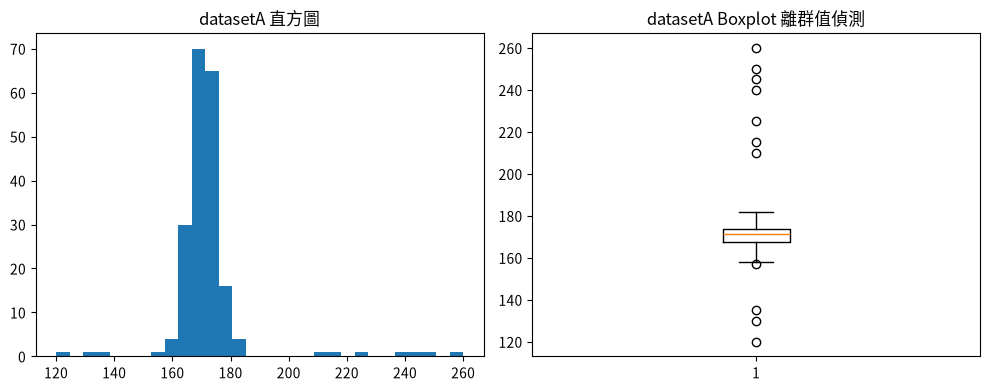

In [4]:
analyze("A")

## datasetB

=== datasetB ===
count    200.000
mean      54.411
std       26.196
min      -20.000
25%       44.431
50%       50.341
75%       56.162
max      200.000
Z-score離群值： [140.0, 150.0, 160.0, 170.0, 180.0, 190.0, 200.0]
IQR離群值： [75.32, 76.64, -20.0, -10.0, 0.0, 120.0, 130.0, 140.0, 150.0, 160.0, 170.0, 180.0, 190.0, 200.0]


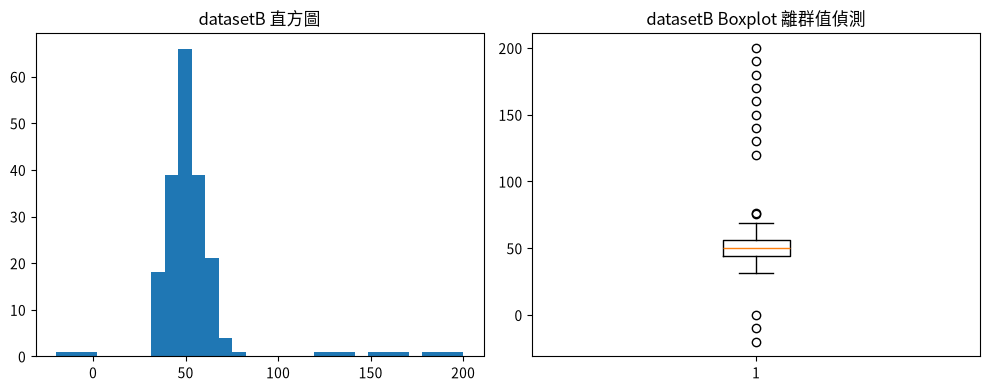

In [5]:
analyze("B")

## datasetC

=== datasetC ===
count      200.000
mean       512.412
std       2774.692
min         13.753
25%         36.480
50%         51.824
75%         77.071
max      30000.000
Z-score離群值： [12000.0, 20000.0, 30000.0]
IQR離群值： [153.98, 141.52, 400.0, 500.0, 600.0, 800.0, 1000.0, 1500.0, 2000.0, 2500.0, 3000.0, 4000.0, 6000.0, 8000.0, 12000.0, 20000.0, 30000.0]


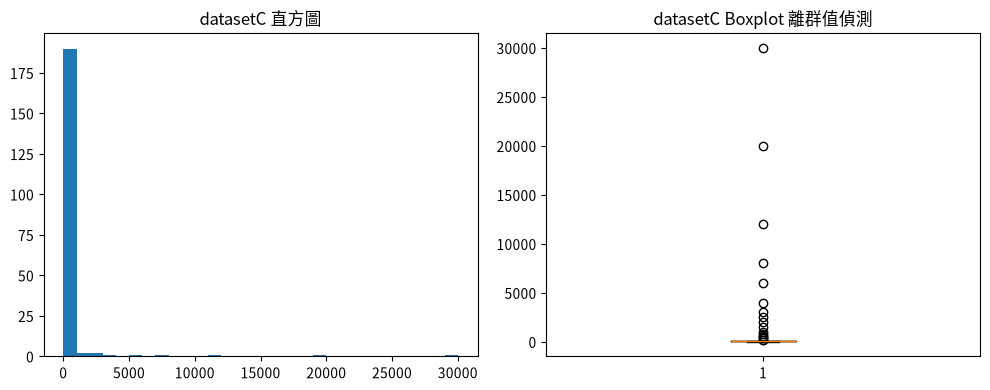

In [6]:
analyze("C")

## datasetD

=== datasetD ===
count    200.000
mean      99.479
std       14.350
min       40.000
25%       91.606
50%       98.471
75%      105.006
max      180.000
Z-score離群值： [40.0, 45.0, 160.0, 170.0, 180.0]
IQR離群值： [137.52, 40.0, 45.0, 160.0, 170.0, 180.0]


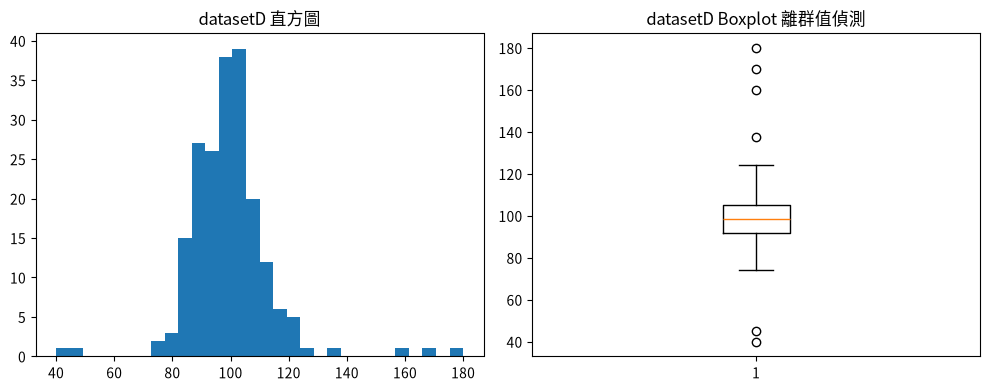

In [7]:
analyze("D")

## datasetE

=== datasetE ===
count    200.000
mean      51.740
std       32.618
min      -10.000
25%       19.544
50%       73.708
75%       79.956
max      170.000
Z-score離群值： [150.0, 170.0]
IQR離群值： []


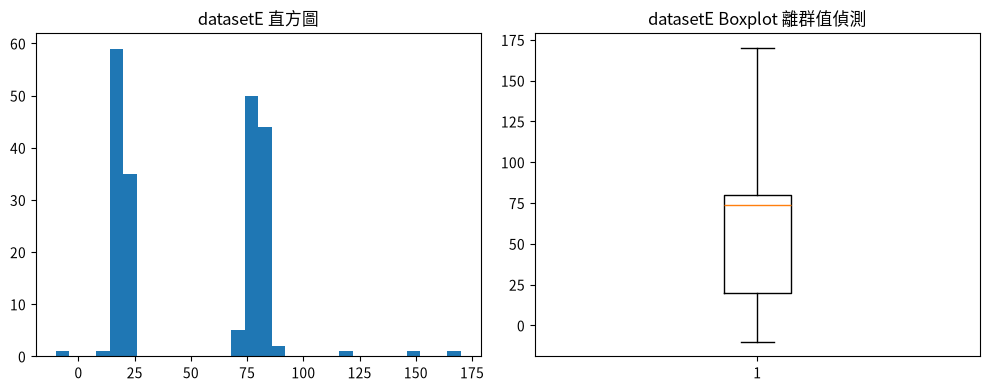

In [8]:
analyze("E")

## 4. 彙整表

把五個 dataset 的統計量與兩種方法的離群值數量整理成表，並存成 `summary.csv`。

In [9]:
summary = pd.DataFrame(rows).set_index("dataset")
summary.round(4).to_csv("summary.csv")
pd.set_option("display.width", 200)
summary.round(3)

,n,mean,median,std,min,max,skew,kurtosis,shapiro_p,Q1,Q3,IQR,z_outliers,iqr_outliers
dataset,,,,,,,,,,,,,,
A,200,172.174,171.124,14.148,120.000,260.0,3.243,18.398,0.0,167.379,173.650,6.272,7,11
B,200,54.411,50.341,26.130,-20.000,200.0,3.221,14.033,0.0,44.431,56.162,11.732,7,14
C,200,512.412,51.824,2767.747,13.753,30000.0,8.300,75.556,0.0,36.480,77.071,40.591,3,17
D,200,99.479,98.471,14.314,40.000,180.0,1.327,9.914,0.0,91.606,105.006,13.400,5,6
E,200,51.740,73.708,32.537,-10.000,170.0,0.262,-0.779,0.0,19.544,79.956,60.411,2,0
